In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('/content/weatherAUS.csv')

print(df.head())

         Date Location  MinTemp  MaxTemp  Rainfall  Evaporation  Sunshine  \
0  01-12-2008   Albury     13.4     22.9       0.6          NaN       NaN   
1  02-12-2008   Albury      7.4     25.1       0.0          NaN       NaN   
2  03-12-2008   Albury     12.9     25.7       0.0          NaN       NaN   
3  04-12-2008   Albury      9.2     28.0       0.0          NaN       NaN   
4  05-12-2008   Albury     17.5     32.3       1.0          NaN       NaN   

  WindGustDir  WindGustSpeed WindDir9am  ... Humidity9am  Humidity3pm  \
0           W           44.0          W  ...        71.0         22.0   
1         WNW           44.0        NNW  ...        44.0         25.0   
2         WSW           46.0          W  ...        38.0         30.0   
3          NE           24.0         SE  ...        45.0         16.0   
4           W           41.0        ENE  ...        82.0         33.0   

   Pressure9am  Pressure3pm  Cloud9am  Cloud3pm  Temp9am  Temp3pm  RainToday  \
0       1007.7    

In [ ]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Shape:
(145460, 23)

Column Names:
['Date', 'Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'RainTomorrow']

Data Types:
Date              object
Location          object
MinTemp          float64
MaxTemp          float64
Rainfall         float64
Evaporation      float64
Sunshine         float64
WindGustDir       object
WindGustSpeed    float64
WindDir9am        object
WindDir3pm        object
WindSpeed9am     float64
WindSpeed3pm     float64
Humidity9am      float64
Humidity3pm      float64
Pressure9am      float64
Pressure3pm      float64
Cloud9am         float64
Cloud3pm         float64
Temp9am          float64
Temp3pm          float64
RainToday         object
RainTomorrow      object
dtype: object


In [ ]:
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:")
print(missing_values.sum())

Missing Values in Each Column:
Date                 0
Location             0
MinTemp           1485
MaxTemp           1261
Rainfall          3261
Evaporation      62790
Sunshine         69835
WindGustDir      10326
WindGustSpeed    10263
WindDir9am       10566
WindDir3pm        4228
WindSpeed9am      1767
WindSpeed3pm      3062
Humidity9am       2654
Humidity3pm       4507
Pressure9am      15065
Pressure3pm      15028
Cloud9am         55888
Cloud3pm         59358
Temp9am           1767
Temp3pm           3609
RainToday         3261
RainTomorrow      3267
dtype: int64

Total Missing Values:
343248


In [ ]:
df['Date'] = pd.to_datetime(
    df['Date'],
    dayfirst=True,
    errors='coerce'
)

print(df['Date'].head())
print("\nData Type:")
print(df['Date'].dtype)


0   2008-12-01
1   2008-12-02
2   2008-12-03
3   2008-12-04
4   2008-12-05
Name: Date, dtype: datetime64[ns]

Data Type:
datetime64[ns]


In [ ]:
df['Year'] = df['Date'].dt.year

df['Month'] = df['Date'].dt.month

df['Day'] = df['Date'].dt.day

print(df[['Date', 'Year', 'Month', 'Day']].head())

        Date  Year  Month  Day
0 2008-12-01  2008     12    1
1 2008-12-02  2008     12    2
2 2008-12-03  2008     12    3
3 2008-12-04  2008     12    4
4 2008-12-05  2008     12    5


In [ ]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage.sort_values(ascending=False))

Sunshine         48.009762
Evaporation      43.166506
Cloud3pm         40.807095
Cloud9am         38.421559
Pressure9am      10.356799
Pressure3pm      10.331363
WindDir9am        7.263853
WindGustDir       7.098859
WindGustSpeed     7.055548
Humidity3pm       3.098446
WindDir3pm        2.906641
Temp3pm           2.481094
RainTomorrow      2.245978
RainToday         2.241853
Rainfall          2.241853
WindSpeed3pm      2.105046
Humidity9am       1.824557
WindSpeed9am      1.214767
Temp9am           1.214767
MinTemp           1.020899
MaxTemp           0.866905
Location          0.000000
Date              0.000000
Year              0.000000
Month             0.000000
Day               0.000000
dtype: float64


In [ ]:
df = df.drop(columns=['Sunshine'])

print("Updated Dataset Shape:")
print(df.shape)


Updated Dataset Shape:
(145460, 25)


In [ ]:
df = df.dropna(subset=['MaxTemp'])
X = df.drop(columns=['MaxTemp', 'Date', 'RainTomorrow', 'Temp3pm'])
y = df['MaxTemp']
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (144199, 21)
Shape of y: (144199,)


In [ ]:
np.random.seed(42)
indices = np.random.permutation(len(X))
split = int(0.8 * len(X))
train_indices = indices[:split]
test_indices = indices[split:]
X_train = X.iloc[train_indices]
X_test = X.iloc[test_indices]
y_train = y.iloc[train_indices]
y_test = y.iloc[test_indices]
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (115359, 21)
Testing data: (28840, 21)
Training target: (115359,)
Testing target: (28840,)


In [ ]:
print("Missing values in training data:")
print(X_train.isnull().sum())

print("\nMissing values in testing data:")
print(X_test.isnull().sum())

print("\nData types:")
print(X_train.dtypes)


Missing values in training data:
Location             0
MinTemp            484
Rainfall          1990
Evaporation      49712
WindGustDir       7673
WindGustSpeed     7624
WindDir9am        8000
WindDir3pm        2956
WindSpeed9am      1098
WindSpeed3pm      2047
Humidity9am       1420
Humidity3pm       2787
Pressure9am      11253
Pressure3pm      11207
Cloud9am         43935
Cloud3pm         46599
Temp9am            712
RainToday         1990
Year                 0
Month                0
Day                  0
dtype: int64

Missing values in testing data:
Location             0
MinTemp            136
Rainfall           480
Evaporation      12462
WindGustDir       1954
WindGustSpeed     1940
WindDir9am        2105
WindDir3pm         774
WindSpeed9am       294
WindSpeed3pm       535
Humidity9am        352
Humidity3pm        716
Pressure9am       2798
Pressure3pm       2805
Cloud9am         10974
Cloud3pm         11652
Temp9am            181
RainToday          480
Year                 0
M

In [ ]:
numerical_cols = X_train.select_dtypes(include=['number']).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
print("Numerical Columns:")
print(numerical_cols)
print("\nCategorical Columns:")
print(categorical_cols)
print("\nNumber of Numerical Columns:", len(numerical_cols))
print("Number of Categorical Columns:", len(categorical_cols))

Numerical Columns:
['MinTemp', 'Rainfall', 'Evaporation', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Year', 'Month', 'Day']

Categorical Columns:
['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday']

Number of Numerical Columns: 16
Number of Categorical Columns: 5


In [46]:

X_train = X_train.copy()
X_test = X_test.copy()
for col in numerical_cols:

    median_value = np.nanmedian(X_train[col].to_numpy())
    train_values = X_train[col].to_numpy()
    test_values = X_test[col].to_numpy()
    train_values = np.where(np.isnan(train_values), median_value, train_values)
    test_values = np.where(np.isnan(test_values), median_value, test_values)
    X_train[col] = train_values
    X_test[col] = test_values

print("Missing numerical values handled successfully!")

Missing numerical values handled successfully!


In [20]:

for col in categorical_cols:
    train_values = X_train[col].dropna().to_numpy()
    unique_values, counts = np.unique(train_values, return_counts=True)
    mode_value = unique_values[np.argmax(counts)]
    train_values = X_train[col].to_numpy()
    test_values = X_test[col].to_numpy()
    train_values = np.where(pd.isna(train_values), mode_value, train_values)
    test_values = np.where(pd.isna(test_values), mode_value, test_values)
    X_train[col] = train_values
    X_test[col] = test_values

print("Missing categorical values handled successfully!")

Missing categorical values handled successfully!


In [21]:
train_encoded = []
test_encoded = []
category_info = {}
encoded_feature_names = []
for col in categorical_cols:
    categories = np.unique(X_train[col].to_numpy())
    category_info[col] = categories
    categories = categories[1:]#This avoids dummy variable trap. Not hundred percent sure why we do it but we do it so...
    train_encoded_col = (X_train[col].to_numpy()[:, None] == categories).astype(float)
    test_encoded_col = (X_test[col].to_numpy()[:, None] == categories).astype(float)
    train_encoded.append(train_encoded_col)
    test_encoded.append(test_encoded_col)
    for category in categories:
        encoded_feature_names.append(str(col) + "_" + str(category))
print("One-Hot Encoding completed!")

One-Hot Encoding completed!


In [22]:
X_train_num = X_train[numerical_cols].to_numpy(dtype=float)
X_test_num = X_test[numerical_cols].to_numpy(dtype=float)

X_train_encoded = np.hstack(train_encoded)
X_test_encoded = np.hstack(test_encoded)

X_train_final = np.hstack((X_train_num, X_train_encoded))
X_test_final = np.hstack((X_test_num, X_test_encoded))

feature_names = numerical_cols + encoded_feature_names

print("Training data shape:", X_train_final.shape)
print("Testing data shape:", X_test_final.shape)
print("Total features:", len(feature_names))

Training data shape: (115359, 110)
Testing data shape: (28840, 110)
Total features: 110


In [23]:
mean_values = np.mean(X_train_final, axis=0)

std_values = np.std(X_train_final, axis=0)

std_values[std_values == 0] = 1

X_train_scaled = (X_train_final - mean_values) / std_values

X_test_scaled = (X_test_final - mean_values) / std_values

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("Mean of first feature:", np.mean(X_train_scaled[:, 0]))
print("Standard deviation of first feature:", np.std(X_train_scaled[:, 0]))

Training data shape: (115359, 110)
Testing data shape: (28840, 110)
Mean of first feature: 1.644080549541496e-14
Standard deviation of first feature: 0.999999999999988


In [25]:
y_train_np = y_train.to_numpy(dtype=float)
y_test_np = y_test.to_numpy(dtype=float)

print("Training target shape:", y_train_np.shape)
print("Testing target shape:", y_test_np.shape)

Training target shape: (115359,)
Testing target shape: (28840,)


In [27]:
X_train_bias = np.column_stack((np.ones(X_train_scaled.shape[0]),X_train_scaled))

X_test_bias = np.column_stack((np.ones(X_test_scaled.shape[0]),X_test_scaled))

print("Training matrix shape:", X_train_bias.shape)
print("Testing matrix shape:", X_test_bias.shape)

Training matrix shape: (115359, 111)
Testing matrix shape: (28840, 111)


In [30]:
theta = np.linalg.pinv(X_train_bias.T @ X_train_bias) @ X_train_bias.T @ y_train_np

print("Coefficients calculated successfully!")
print("Intercept:", theta[0])
print("Number of weights:", len(theta) - 1)

Coefficients calculated successfully!
Intercept: 23.218880191280892
Number of weights: 110


In [34]:
y_pred = X_test_bias @ theta

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))

print("\nFirst 10 predicted temperatures:")
print(y_pred[:10])

Predictions generated successfully!
Number of predictions: 28840

First 10 predicted temperatures:
[16.64371527 35.4911262  30.14415652 23.57007005 26.04885984 16.31165894
 21.86477972 26.31784626 30.96456287 33.6535096 ]


In [39]:
mae = np.mean(np.abs(y_test_np - y_pred))

mse = np.mean((y_test_np - y_pred) ** 2)

ss_res = np.sum((y_test_np - y_pred) ** 2)

ss_tot = np.sum((y_test_np - np.mean(y_test_np)) ** 2)

r2 = 1 - (ss_res / ss_tot)

print("Model Evaluation Results")
print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("R2 Score:", r2)

Model Evaluation Results
Mean Absolute Error: 1.478132670255512
Mean Squared Error: 3.9025184652968856
R2 Score: 0.922288473913606


In [43]:
y_train_np = y_train.to_numpy()

y_train_pred = X_train_bias @ theta

train_mae = np.mean(np.abs(y_train_np - y_train_pred))
train_mse = np.mean((y_train_np - y_train_pred) ** 2)

train_ss_res = np.sum((y_train_np - y_train_pred) ** 2)
train_ss_tot = np.sum((y_train_np - np.mean(y_train_np)) ** 2)

train_r2 = 1 - (train_ss_res / train_ss_tot)

print("Training R2 Score:", train_r2)
print("Testing R2 Score:", r2)

print("Training MAE:", train_mae)
print("Testing MAE:", mae)

Training R2 Score: 0.9227564260271983
Testing R2 Score: 0.922288473913606
Training MAE: 1.4768644629524355
Testing MAE: 1.478132670255512


In [45]:
rmse = np.sqrt(mse)
train_rmse = np.sqrt(train_mse)
performance_results = pd.DataFrame({'Model': ['NumPy Linear Regression', 'NumPy Linear Regression'],'Dataset': ['Training', 'Testing'],'MAE': [train_mae, mae],'MSE': [train_mse, mse],'RMSE': [train_rmse, rmse],'R2 Score': [train_r2, r2]})
print(performance_results.round(4).to_string(index=False))

                  Model  Dataset    MAE    MSE   RMSE  R2 Score
NumPy Linear Regression Training 1.4769 3.9237 1.9808    0.9228
NumPy Linear Regression  Testing 1.4781 3.9025 1.9755    0.9223


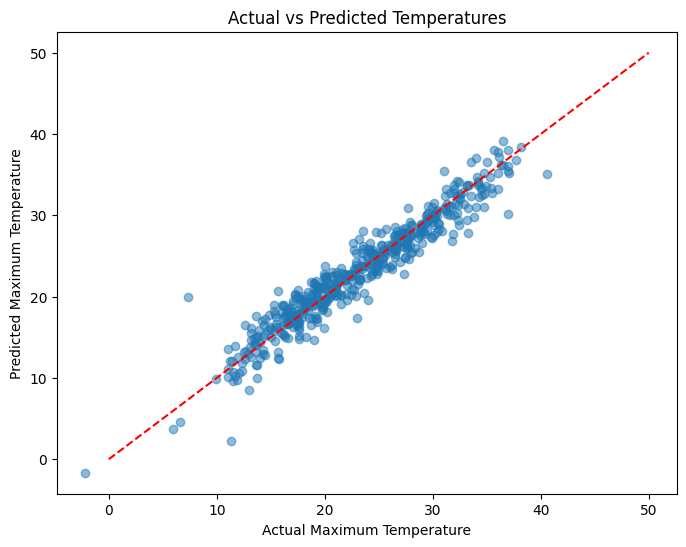

In [42]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test_np[:500], y_pred[:500], alpha=0.5)
plt.xlabel("Actual Maximum Temperature")
plt.ylabel("Predicted Maximum Temperature")
plt.title("Actual vs Predicted Temperatures")
plt.plot([0, 50], [0, 50], 'r--')
plt.show()